# 02 – Next-Hour Electricity Forecasting (Linear Regression, Decision Tree, Random Forest)

**Goal:** predict the household's `Global_active_power` (kW) for the **next hour** using only **past** information.

Why this notebook exists: in `01_data_preprocessing`, `Global_intensity` from the *same minute* explained 99.8% of the target
(power ≈ voltage × current), so the R² of 0.998 was data leakage. Here every feature comes from **before** the hour being predicted.

Steps:
1. Load data and resample to hourly
2. Build features (a small set that a user can also type into the app)
3. Chronological train/test split
4. Baselines
5. The three models: Linear Regression, Decision Tree, Random Forest
6. Compare the models
7. Plots and error analysis
8. Time-series cross-validation
9. Save models and files for the Streamlit app

## Step 1 – Load the data and resample to hourly

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib, os, warnings
warnings.filterwarnings("ignore")

DATA_PATH = "../data/raw/household_power_consumption.txt"   # change if your path is different

df = pd.read_csv(DATA_PATH, sep=";", na_values="?", low_memory=False)
df["Datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], dayfirst=True)
df = df.drop(columns=["Date", "Time"]).set_index("Datetime").sort_index()

print("Minute-level shape:", df.shape)
print("Missing values (minute level):", int(df["Global_active_power"].isna().sum()))

Minute-level shape: (2075259, 7)
Missing values (minute level): 25979


In [2]:
# Minute data -> hourly average (NaNs are ignored inside each hour)
hourly = df.resample("h").mean()

# Fill only SHORT gaps (max 6 hours); hours still missing after that are dropped
print("Missing hours before filling:", int(hourly["Global_active_power"].isna().sum()))
hourly = hourly.interpolate(method="time", limit=6)
hourly = hourly.dropna(subset=["Global_active_power"])

print("Hourly shape:", hourly.shape)
hourly.head()

Missing hours before filling: 421
Hourly shape: (34211, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


## Step 2 – Feature engineering (only past information)

Every feature for hour `t` uses data from hour `t-1` or earlier, plus the calendar.
We keep the feature set **small on purpose**, so that in the Streamlit app a user can enter all the inputs by hand:

| Feature | Meaning | Entered by user in the app? |
|---|---|---|
| `lag_1` | usage 1 hour ago (kW) | yes |
| `lag_2` | usage 2 hours ago (kW) | yes |
| `lag_24` | usage at the same hour yesterday (kW) | yes |
| `roll_mean_24` | average usage over the last 24 hours (kW) | yes |
| `hour_sin`, `hour_cos` | hour of day (cyclical) | from the chosen hour |
| `day_of_week`, `is_weekend`, `month` | calendar | from the chosen date |

In [3]:
target = "Global_active_power"
t = hourly[target]

data = pd.DataFrame(index=hourly.index)
data["y"] = t                                     # what we want to predict (hour t)

# --- Past usage ---
data["lag_1"]  = t.shift(1)                       # 1 hour ago
data["lag_2"]  = t.shift(2)                       # 2 hours ago
data["lag_24"] = t.shift(24)                      # same hour yesterday
data["roll_mean_24"] = t.shift(1).rolling(24).mean()   # average of the previous 24 hours (hour t excluded)

# --- Calendar features (known in advance) ---
data["hour_sin"] = np.sin(2 * np.pi * data.index.hour / 24)   # cyclical: 23h and 0h are "close"
data["hour_cos"] = np.cos(2 * np.pi * data.index.hour / 24)
data["day_of_week"] = data.index.dayofweek
data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)
data["month"] = data.index.month

data = data.dropna()
print("Final dataset shape:", data.shape)
data.head()

Final dataset shape: (34187, 10)


,y,lag_1,lag_2,lag_24,roll_mean_24,hour_sin,hour_cos,day_of_week,is_weekend,month
Datetime,,,,,,,,,,
2006-12-17 17:00:00,3.406767,3.326033,2.985400,4.222889,2.499145,-0.965926,-2.588190e-01,6,1,12
2006-12-17 18:00:00,3.697100,3.406767,3.326033,3.632200,2.465140,-1.000000,-1.836970e-16,6,1,12
2006-12-17 19:00:00,2.908400,3.697100,3.406767,3.400233,2.467844,-0.965926,2.588190e-01,6,1,12
2006-12-17 20:00:00,3.361500,2.908400,3.697100,3.268567,2.447351,-0.866025,5.000000e-01,6,1,12
2006-12-17 21:00:00,3.040767,3.361500,2.908400,3.056467,2.451224,-0.707107,7.071068e-01,6,1,12


## Step 3 – Chronological train / test split

In [4]:
features = [c for c in data.columns if c != "y"]
X, y = data[features], data["y"]

split = int(len(data) * 0.8)                      # first 80% of time = train, last 20% = test
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Train:", X_train.index.min().date(), "->", X_train.index.max().date(), "|", X_train.shape)
print("Test :", X_test.index.min().date(),  "->", X_test.index.max().date(),  "|", X_test.shape)

Train: 2006-12-17 -> 2010-02-05 | (27349, 9)
Test : 2010-02-05 -> 2010-11-26 | (6838, 9)


## Step 4 – Baselines
A model is only useful if it beats this simple rule.

In [5]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = {}
preds = {}

def evaluate(name, y_true, y_pred):
    results[name] = {
        "MAE":  mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2":   r2_score(y_true, y_pred),
    }
    preds[name] = np.asarray(y_pred)

# Baseline: next hour = this hour (not a learning algorithm, just a reference)
evaluate("Naive baseline (last hour)", y_test, X_test["lag_1"])
pd.DataFrame(results).T.round(4)

,MAE,RMSE,R2
Naive baseline (last hour),0.3959,0.6022,0.3441


## Step 5 – The three models

In [6]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Decision Tree":     DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42),
    "Random Forest":     RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5,
                                               random_state=42, n_jobs=-1),
}

fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    evaluate(name, y_test, model.predict(X_test))
    print(f"{name:20s} trained")

Linear Regression    trained
Decision Tree        trained
Random Forest        trained


## Step 6 – Compare the models

In [7]:
comparison = pd.DataFrame(results).T.sort_values("RMSE")
comparison.round(4)

,MAE,RMSE,R2
Random Forest,0.3330,0.4807,0.5821
Decision Tree,0.3485,0.5006,0.5467
Linear Regression,0.3745,0.5274,0.4969
Naive baseline (last hour),0.3959,0.6022,0.3441


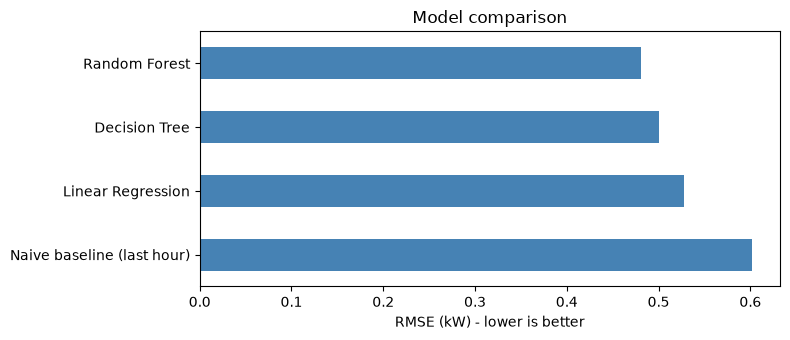

In [8]:
ax = comparison["RMSE"].plot(kind="barh", figsize=(8, 3.5), color="steelblue")
ax.set_xlabel("RMSE (kW) - lower is better")
ax.set_title("Model comparison")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

## Step 7 – Plots and error analysis

Best model: Random Forest


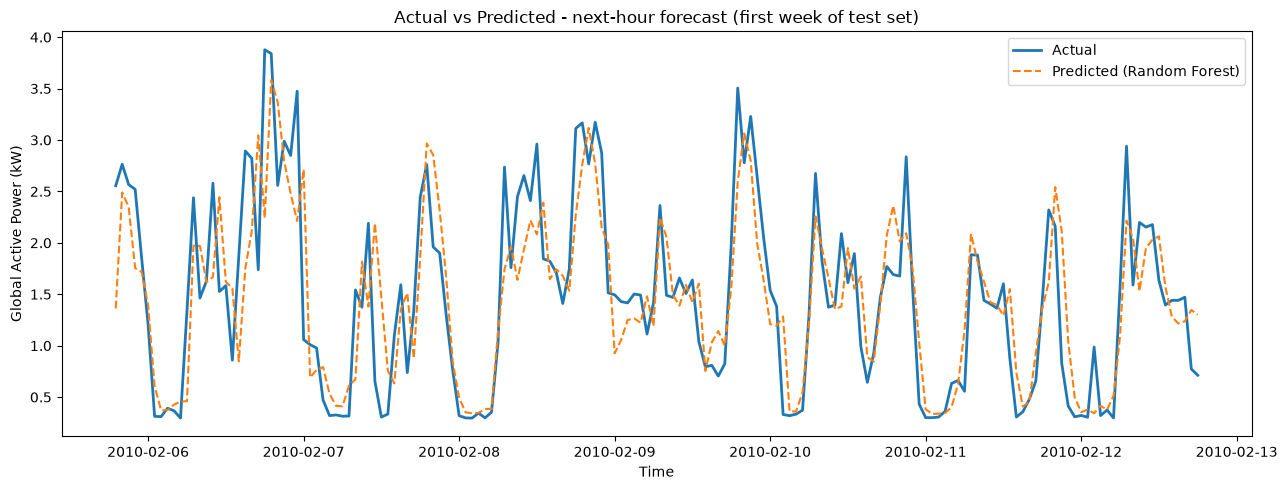

In [9]:
ml_names = list(models.keys())
best_name = comparison[comparison.index.isin(ml_names)].index[0]   # best of the three ML models (lowest RMSE)
print("Best model:", best_name)

# Actual vs predicted: first 7 days of the test set
n = 24 * 7
plt.figure(figsize=(13, 5))
plt.plot(y_test.index[:n], y_test.values[:n], label="Actual", linewidth=2)
plt.plot(y_test.index[:n], preds[best_name][:n], label=f"Predicted ({best_name})", linestyle="--")
plt.xlabel("Time"); plt.ylabel("Global Active Power (kW)")
plt.title("Actual vs Predicted - next-hour forecast (first week of test set)")
plt.legend(); plt.tight_layout(); plt.show()

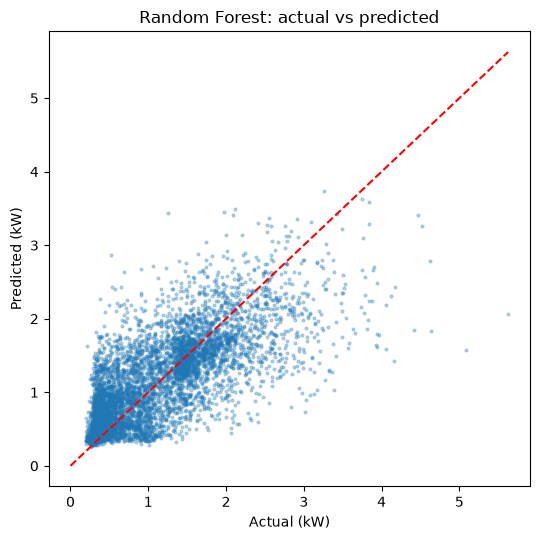

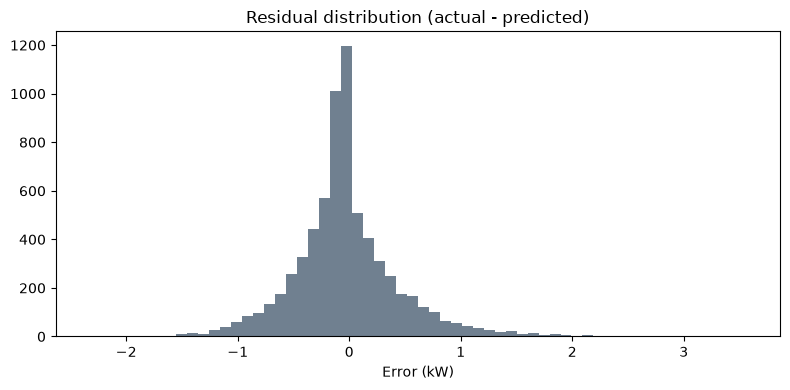

In [10]:
# Scatter: actual vs predicted
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, preds[best_name], s=4, alpha=0.3)
lim = [0, max(y_test.max(), preds[best_name].max())]
plt.plot(lim, lim, "r--")
plt.xlabel("Actual (kW)"); plt.ylabel("Predicted (kW)")
plt.title(f"{best_name}: actual vs predicted")
plt.tight_layout(); plt.show()

# Residuals
residuals = y_test.values - preds[best_name]
plt.figure(figsize=(8, 4))
plt.hist(residuals, bins=60, color="slategray")
plt.title("Residual distribution (actual - predicted)")
plt.xlabel("Error (kW)"); plt.tight_layout(); plt.show()

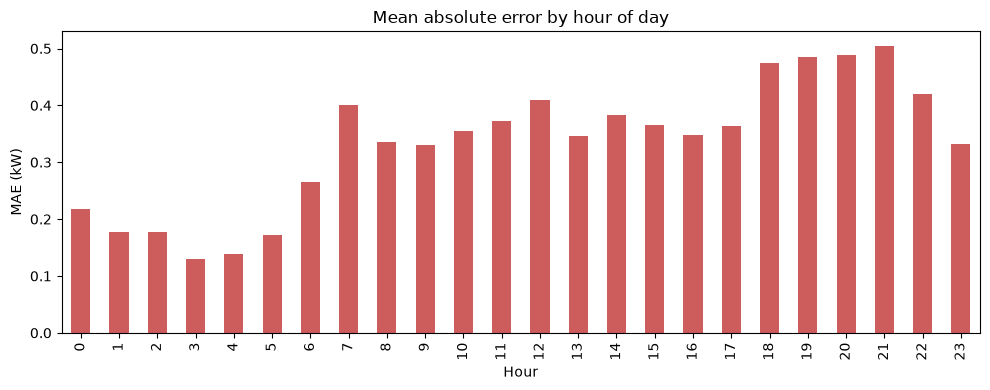

In [11]:
# Where does the model make the biggest errors? (by hour of day)
test_hours = X_test.index.hour
err = pd.DataFrame({"abs_err": np.abs(residuals), "hour": test_hours})
err.groupby("hour")["abs_err"].mean().plot(kind="bar", figsize=(10, 4), color="indianred")
plt.title("Mean absolute error by hour of day")
plt.xlabel("Hour"); plt.ylabel("MAE (kW)")
plt.tight_layout(); plt.show()

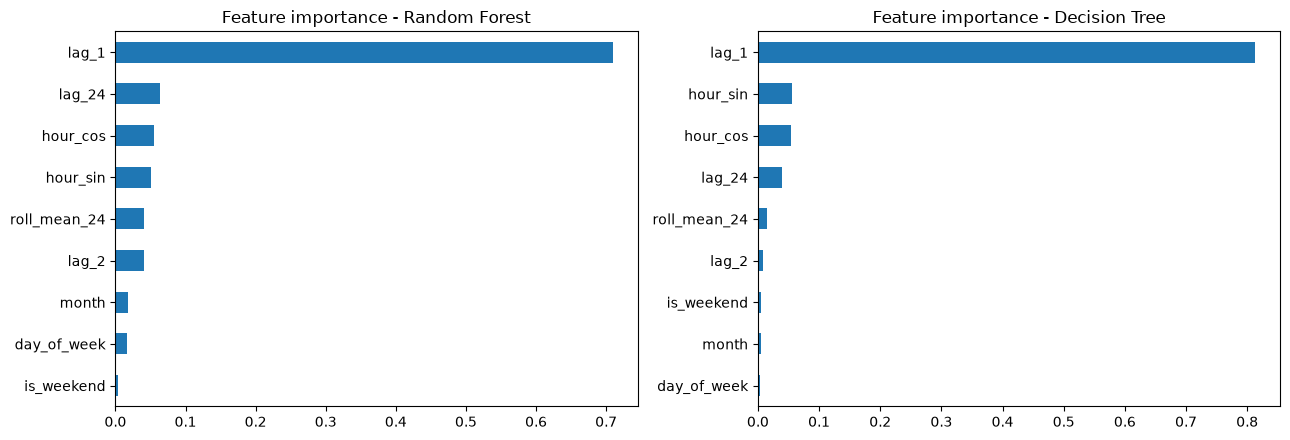

In [12]:
# Feature importance of the Random Forest and the Decision Tree
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, name in zip(axes, ["Random Forest", "Decision Tree"]):
    imp = pd.Series(fitted[name].feature_importances_, index=features).sort_values()
    imp.plot(kind="barh", ax=ax)
    ax.set_title(f"Feature importance - {name}")
plt.tight_layout(); plt.show()

## Step 8 – Time-series cross-validation
Checks the result is not just luck on one test period.

In [13]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.base import clone

tscv = TimeSeriesSplit(n_splits=5)
cv_rows = []
for name, model in models.items():
    for fold, (tr, te) in enumerate(tscv.split(X), 1):
        m = clone(model).fit(X.iloc[tr], y.iloc[tr])
        p = m.predict(X.iloc[te])
        cv_rows.append({"model": name, "fold": fold,
                        "RMSE": np.sqrt(mean_squared_error(y.iloc[te], p)),
                        "R2": r2_score(y.iloc[te], p)})

cv = pd.DataFrame(cv_rows)
cv_summary = cv.groupby("model")[["RMSE", "R2"]].agg(["mean", "std"]).round(4)
cv_summary

RMSE              R2        
                     mean     std    mean     std
model                                            
Decision Tree      0.5726  0.0679  0.5555  0.0329
Linear Regression  0.5902  0.0622  0.5271  0.0297
Random Forest      0.5448  0.0681  0.5981  0.0302

## Step 9 – Save everything the Streamlit app needs

In [14]:
os.makedirs("../models", exist_ok=True)
os.makedirs("../data/processed", exist_ok=True)

# All three models in one file, plus the feature order the app must use
joblib.dump({"models": fitted, "features": features, "best": best_name},
            "../models/models.pkl", compress=3)

comparison.round(4).to_csv("../models/model_comparison.csv")
data.round(4).to_csv("../data/processed/features.csv")
print("Saved models.pkl, model_comparison.csv and features.csv. Best model:", best_name)

Saved models.pkl, model_comparison.csv and features.csv. Best model: Random Forest


## Summary (fill in after running)
- Best model: ...
- Best model RMSE / MAE / R²: ...
- Improvement over the naive baseline: ...
- Linear Regression vs Decision Tree vs Random Forest: ...
- Hardest hours to predict: ...
- Limitations: one household, missing-data interpolation, no weather data.